# Applied Statistics: Iris Dataset Analysis

## Problems Overview

Below are the 4 probelms that need to be solved

### Problem 1: Exploring Petal Length

The Iris dataset contains measurements of 150 iris flowers belonging to three species: setosa, versicolor, and virginica. For each flower, the dataset records sepal length, sepal width, petal length, and petal width.

Using the Iris dataset, investigate the distribution of petal_length.

1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

### Problem 2: Correlation Between Petal Length and Petal Width

Investigate the relationship between petal_length and petal_width in the Iris dataset.

1. Calculate the Pearson correlation coefficient between petal length and petal width using all 150 flowers.
2. Create an appropriate scatter plot showing the relationship between the two variables, and include a suitable line to help illustrate the relationship.
3. Calculate the Pearson correlation coefficient separately for each of the three species.
4. Create an appropriate plot showing the relationship between petal length and petal width for each species.
5. Report and compare the correlation coefficients.
6. Explain what the correlation coefficients tell you about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

### Problem 3: Comparing Species Using t-Tests

Investigate whether the three iris species differ in their petal_length and petal_width.

For each pair of species:

- setosa vs versicolor
- setosa vs virginica
- versicolor vs virginica

perform an independent-samples t-test for:

- petal length,
- petal width.

For each test:

1. State the null and alternative hypotheses.
2. Calculate the t-statistic and p-value using scipy.stats.
3. Use a significance level of α = 0.05 to decide whether to reject the null hypothesis.
4. Summarise your results in an appropriate table.
5. Explain what the results tell you about differences between the three species.

### Problem 4: Comparing the Species Using ANOVA

The t-tests in Problem 3 require several separate comparisons between species. Instead, investigate differences in petal length and petal width using one-way analysis of variance (ANOVA).

For each variable:

1. State the null and alternative hypotheses for a one-way ANOVA.
2. Perform a one-way ANOVA comparing the three species using scipy.stats.
3. Report the F-statistic and p-value.
4. Use a significance level of α = 0.05 to determine whether there is evidence that the species have different population means.
5. Explain what the ANOVA result tells you and what it does not tell you about the individual species.

The t-tests in Problem 3 involved three pairwise comparisons. Explain why performing several separate hypothesis tests can increase the overall probability of making a type I error, and explain how ANOVA addresses this problem by testing the three group means simultaneously.

Finally, compare the conclusions from the t-tests with those from the ANOVA and explain why ANOVA is generally preferable when comparing more than two groups.

## Problem Solutions

### Imports and Loading Iris Dataset

In [1]:
import sklearn as skl
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

from sklearn import datasets
from scipy.stats import norm, pearsonr

iris = datasets.load_iris()

In [2]:
# provides variable names for each target allowing for more efficient coding and manipulation
target = iris.target
target_names = iris.target_names
data = iris.data


### Problem 1: Exploring Petal Length

Below is the code used to solve Problem 1, each part of the Problem is labelled before the code.

In [3]:
# Extract Petal Length for all 150 flowers
petal_length = data[:, 2]

In [4]:
# Create folder for saving figures if it doesn't exist
os.makedirs("Histograms", exist_ok=True)

#### Problem 1: Part 1
#### Histogram of all petal lengths with normal curve

In [5]:
# Calculate mean and standard deviation
mean_length = np.mean(petal_length)
std_length = np.std(petal_length)
print(mean_length, std_length)

3.7580000000000005 1.759404065775303


In [6]:
# Create x-values for the normal distribution curve
x = np.linspace(petal_length.min(), petal_length.max(), 300)

# Calculate normal probability density
normal_curve = norm.pdf(x, mean_length, std_length)

#### Problem 1: Part 2

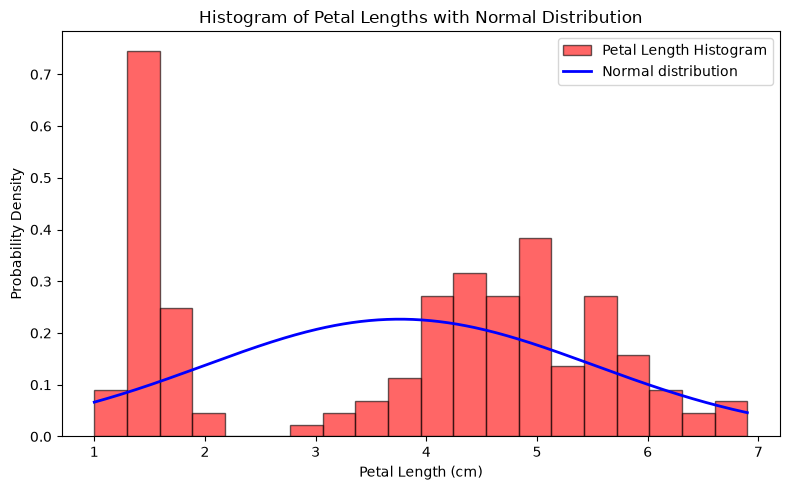

In [7]:
# Plot Histogram
plt.figure(figsize=(8, 5))
plt.hist(
    petal_length,
    bins=20,
    density=True,
    color="red",
    edgecolor="black",
    alpha=0.6,
    label="Petal Length Histogram"
)

# Superimpose normal distribution
plt.plot(
    x,
    normal_curve,
    color="blue",
    linewidth=2,
    label="Normal distribution"
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Probability Density")
plt.title("Histogram of Petal Lengths with Normal Distribution")
plt.legend()
plt.tight_layout()
plt.savefig(
    "Histograms/Petal Length Normal Distribution.png",
    dpi=300
)
plt.show()

#### Problem 1: Part 3

In [8]:
# Boolean index to select the petal length of each species
setosa_petal_length = data[target == 0, 2]
versicolor_petal_length = data[target == 1, 2]
virginica_petal_length = data[target == 2, 2]

In [9]:
# Boolean index to select the petal width of each species
setosa_petal_width = data[target == 0, 3]
versicolor_petal_width = data[target == 1,3 ]
virginica_petal_width = data[target ==  2, 3]

In [10]:
# Store each species' name and petal lengths, assign a colour to each for histogram differentiation
species_data = [
    ("Setosa", setosa_petal_length, setosa_petal_width, "green"),
    ("Versicolor", versicolor_petal_length, versicolor_petal_width, "yellow"),
    ("Virginica", virginica_petal_length, virginica_petal_width, "blue")
]

# Calculate and print the mean and standard deviation
for species_name, lengths, widths, species_color in species_data:
    mean_length = np.mean(lengths)
    std_length = np.std(lengths)
    
    print(f"{species_name}: mean = {mean_length:.2f}, std = {std_length:.2f}")

Setosa: mean = 1.46, std = 0.17
Versicolor: mean = 4.26, std = 0.47
Virginica: mean = 5.55, std = 0.55


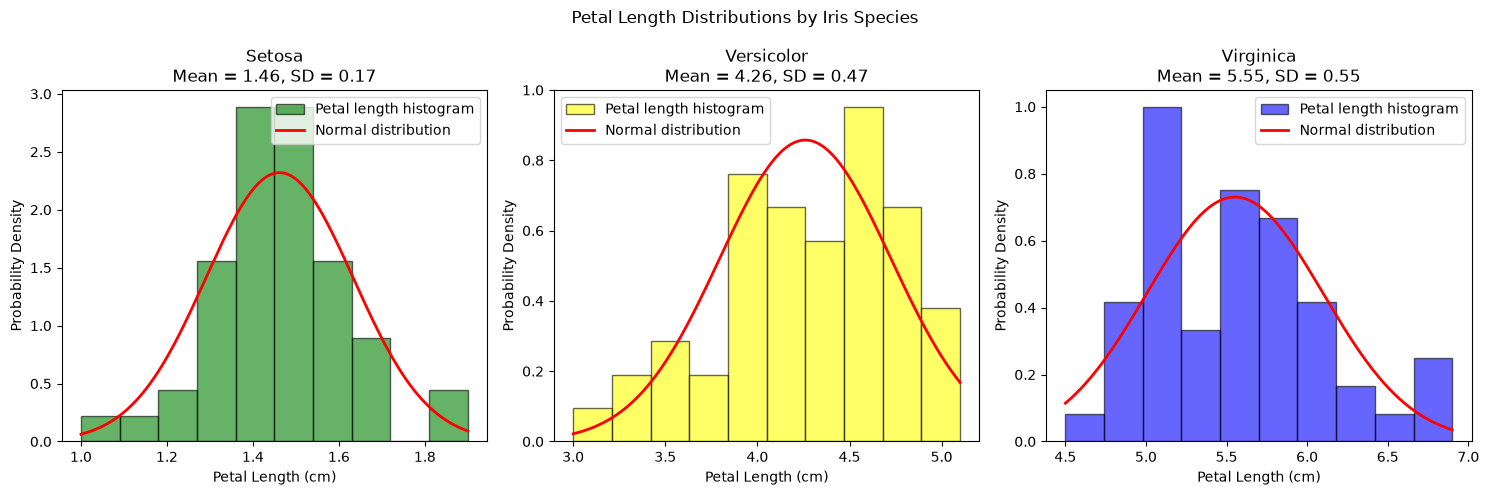

In [11]:
# Create three separate plots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (species_name, lengths, widths, species_color) in zip(axes, species_data):

    # Calculate mean and standard deviation for this species
    mean_length = np.mean(lengths)
    std_length = np.std(lengths)

    # Generate x-values and calculate normal distribution
    x = np.linspace(lengths.min(), lengths.max(), 300)
    normal_curve = norm.pdf(x, mean_length, std_length)

    # Plot histogram
    ax.hist(
        lengths,
        bins=10,
        density=True,
        color=species_color,
        edgecolor="black",
        alpha=0.6,
        label="Petal length histogram"
    )

    # Superimpose normal distribution
    ax.plot(
        x,
        normal_curve,
        color="red",
        linewidth=2,
        label="Normal distribution"
    )

    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Probability Density")
    ax.set_title(
        f"{species_name}\nMean = {mean_length:.2f}, "
        f"SD = {std_length:.2f}"
    )
    ax.legend()

fig.suptitle("Petal Length Distributions by Iris Species")
plt.tight_layout()
plt.savefig(
    "Histograms/Petal Length Distributions by Species.png",
    dpi=300
)
plt.show()


### Problem 1: Part 4
The mean and standard deviation of petal length were calculated for the complete Iris dataset and for each of the three individual species. The mean represents the average petal length, while the standard deviation indicates the degree of variation in measurements around the mean. The results are presented below, rounded to two decimal places.

In [12]:
# Calculate mean and standard deviation for the complete dataset
overall_mean = np.mean(data[:, 2])
overall_std = np.std(data[:, 2])

# Create a list to store the results
results = [
    {
        "Species": "Overall",
        "Mean": overall_mean,
        "Standard Deviation": overall_std
    },
    {
        "Species": "Setosa",
        "Mean": np.mean(setosa_petal_length),
        "Standard Deviation": np.std(setosa_petal_length)
    },
    {
        "Species": "Versicolor",
        "Mean": np.mean(versicolor_petal_length),
        "Standard Deviation": np.std(versicolor_petal_length)
    },
    {
        "Species": "Virginica",
        "Mean": np.mean(virginica_petal_length),
        "Standard Deviation": np.std(virginica_petal_length)
    }
]

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Save the results to a CSV file
results_df.round(2).to_csv(
    "Histograms/Petal Length Statistics.csv",
    index=False
)

# Display the results in the notebook
display(results_df.round(2))


,Species,Mean,Standard Deviation
0,Overall,3.76,1.76
1,Setosa,1.46,0.17
2,Versicolor,4.26,0.47
3,Virginica,5.55,0.55


#### Problem 1: Part 5
#### Histogram of Petal Length with Normal Distribution

The histogram of petal lengths for all 150 flowers shows that the overall distribution does not fit normal distribution. The histogram show the data for all 3 of the Iris flower species. Setosa is considerably shorter than Virginica and Veriscolour, with Virginica having the longest petal length. As a result, the overall distribution is asymmetrical and does not fit well into a normal distribution bell-curve. Overall, a single normal distribution is not a suitable model to use for petal length when all species are combined.

#### Petal Length Distribution by Iris Species
#### Setosa

When examining the Iris species separately, their distributions become more concentrated around their means. Setosa has the shortest mean petal length (1.46 cm), and the smallest standard deviation (0.17 cm). Although the histogram is not perfectly symmetrical, it's petal lengths are group more closely together and the normal distribution provides a more reasonable approximation of general shape.

#### Veriscolor

Veriscolor has a mean petal length of approximately 4.26cm and standard deviation of 0.47 cm. It's distribution is more spread out than that of Setosa, and is concentrated around the mean. Compared with Setosa, Veriscolor displays greater variation in petal length as evidenced by the increased standard deviation. The histogram shows a general concentration of values around the centre , with fewer observations towards the low end of the histogram. The normal distribution shows a reasonable approximation of it's general shape, although there are some differences between the histogram and theoretical curve. This suggests that petal length within Versicolor may be reasonably modelled using a normal distribution, but the fit is not perfect.

#### Virginica

Virginica has the longest petal length with a mean petal length, approximately 5.55 cm, with the largest standard deviation of 0.55 cm. This indicates that on average Virginica has the longest petals of the 3 species, but also the greatest variation as evidenced by the standard deviation. The distribution is centred around a higher mean that Setosa or Veriscolor, with observations spread across a wider range of values. Despite this greater variation, many of the observations are centred around the mean. The normal distribution provides a general approximation of the observed distribution, although the histogram does not perfectly fit the bell-shaped curve. This suggests that a normal distribution may be a reasonable model for Virginica, but it does not fully capture every feature of the observed data.

#### Overall

The comparison shows that petal length differs considerably between the three Iris species. Setosa has the shortest average petal length and the smallest standard deviation, indicating that its measurements are the most closely grouped. Versicolor has an intermediate average petal length and a greater spread of observations, while Virginica has the longest average petal length and the greatest variation.

Although normal distributions may provide reasonable approximations for the individual species, a single normal distribution is not appropriate for the combined dataset of the 3 species. This is because the overall histogram contains three distinct groupings, corresponding to the different species, rather than one central peak with a symmetrical spread. This produces a distribution that does not follow the typical bell-shaped pattern expected of a normal distribution. By examining each species separately this provides a clearer understanding of the distribution of petal lengths and demonstrates why it is important to consider the underlying groups when analysing the dataset.

### Problem 2: Correlation Between Petal Length and Petal Width

Below is the code used to solve Problem 2...

#### Problem 2: Part 1

In [13]:
# Extract petal length and petal width for all 150 flowers
petal_length = data[:, 2]
petal_width = data[:, 3]

# Calculate the Pearson correlation coefficient
correlation, p_value = pearsonr(petal_length, petal_width)

# Display the correlation coefficient to four decimal places
print(f"Pearson correlation coefficient: {correlation:.4f}")

Pearson correlation coefficient: 0.9629


#### Problem 2: Part 2

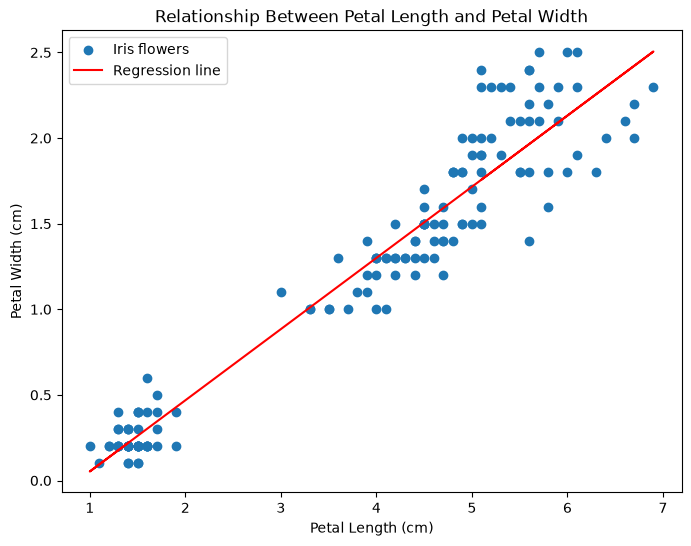

In [14]:

# Create a scatter plot showing petal length and petal width
plt.figure(figsize=(8, 6))

# Plot the observations
plt.scatter(petal_length, petal_width, label="Iris flowers")

# Calculate the linear regression coefficients
slope, intercept = np.polyfit(petal_length, petal_width, 1)

# Generate values for the regression line
regression_line = slope * petal_length + intercept

# Plot the regression line
plt.plot(petal_length, regression_line, color="red", label="Regression line")

# Add labels and title
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Relationship Between Petal Length and Petal Width")

# Display the legend and plot
plt.legend()
plt.show()


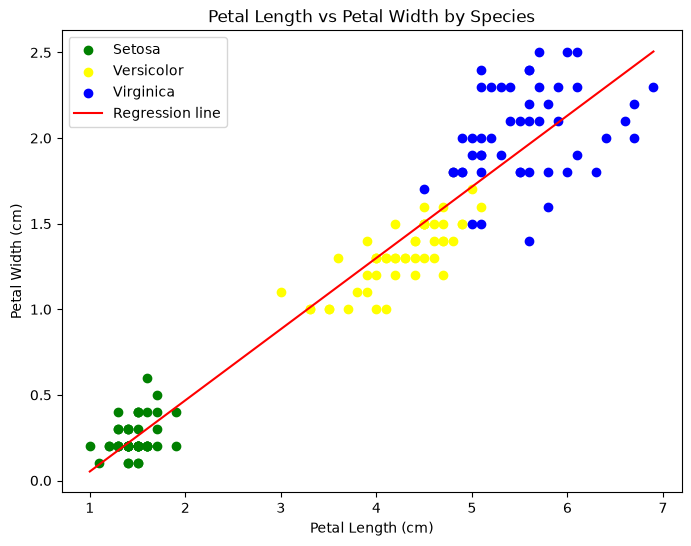

In [15]:
# Create a scatter plot showing petal length and petal width for each species
plt.figure(figsize=(8, 6))

# Plot Setosa observations
plt.scatter(setosa_petal_length, setosa_petal_width,
            color="green", label="Setosa")

# Plot Versicolor observations
plt.scatter(versicolor_petal_length, versicolor_petal_width,
            color="yellow", label="Versicolor")

# Plot Virginica observations
plt.scatter(virginica_petal_length, virginica_petal_width,
            color="blue", label="Virginica")

# Calculate the overall linear regression coefficients
slope, intercept = np.polyfit(petal_length, petal_width, 1)

# Generate values for the regression line
x_line = np.linspace(petal_length.min(), petal_length.max(), 100)
regression_line = slope * x_line + intercept

# Plot the overall regression line
plt.plot(x_line, regression_line, color="red", label="Regression line")

# Add labels and title
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Petal Length vs Petal Width by Species")

# Display the legend and plot
plt.legend()
plt.show()


#### Problem 2: Part 3

In [16]:
# Calculate Pearson correlation for each species
setosa_corr, _ = pearsonr(setosa_petal_length, setosa_petal_width)
versicolor_corr, _ = pearsonr(versicolor_petal_length, versicolor_petal_width)
virginica_corr, _ = pearsonr(virginica_petal_length, virginica_petal_width)

# Display the correlation coefficients
print(f"Setosa: {setosa_corr:.4f}")
print(f"Versicolor: {versicolor_corr:.4f}")
print(f"Virginica: {virginica_corr:.4f}")

Setosa: 0.3316
Versicolor: 0.7867
Virginica: 0.3221


#### Problem 3: Part 4

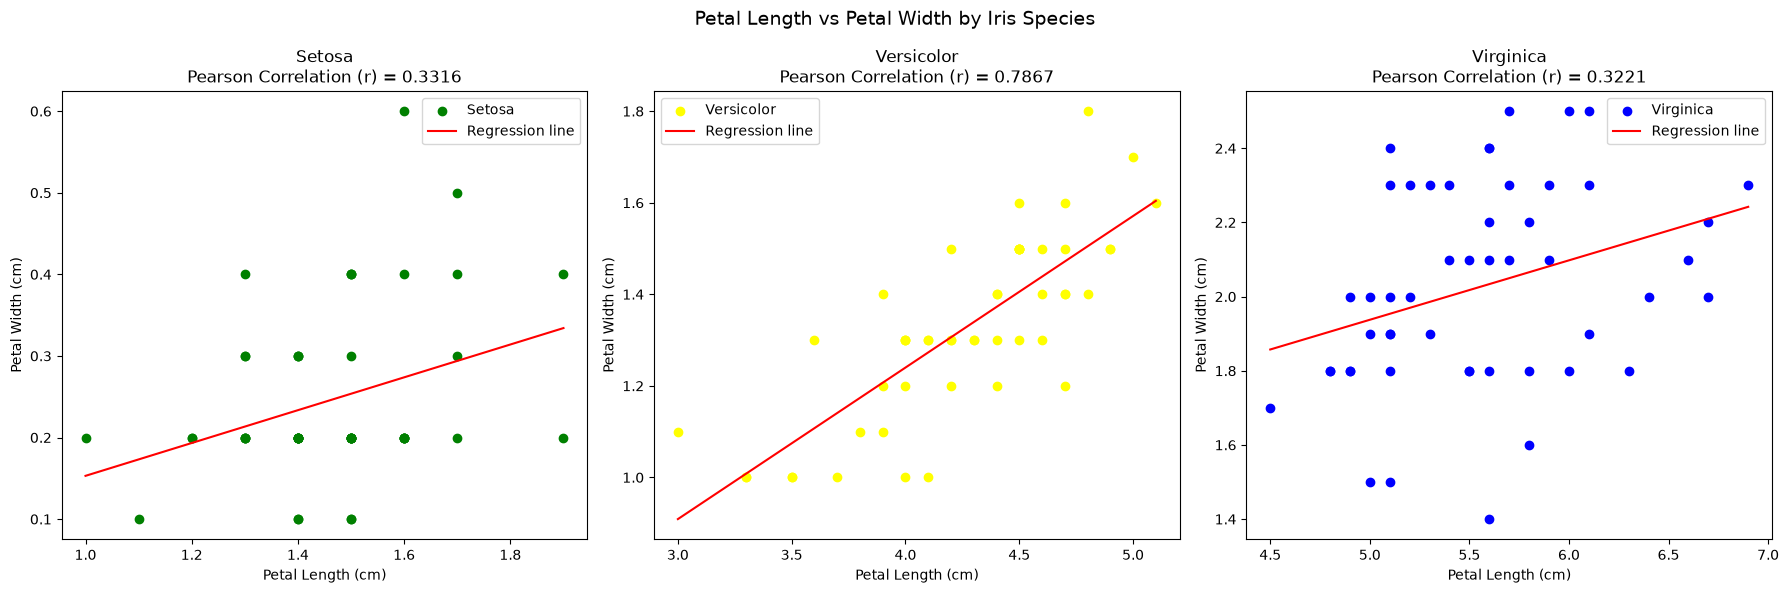

In [19]:
# Create three scatter plots, one for each Iris species
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Store species names, petal lengths, petal widths and colours
species_data = [
    ("Setosa", setosa_petal_length, setosa_petal_width, "green"),
    ("Versicolor", versicolor_petal_length, versicolor_petal_width, "yellow"),
    ("Virginica", virginica_petal_length, virginica_petal_width, "blue")
]

# Generate a scatter plot and regression line for each species
for ax, (species_name, lengths, widths, species_color) in zip(axes, species_data):

    # Plot the observations
    ax.scatter(lengths, widths, color=species_color, label=species_name)

    # Calculate the Pearson correlation coefficient
    correlation, p_value = pearsonr(lengths, widths)

    # Calculate the linear regression coefficients
    slope, intercept = np.polyfit(lengths, widths, 1)

    # Generate values for the regression line
    x_line = np.linspace(lengths.min(), lengths.max(), 100)
    regression_line = slope * x_line + intercept

    # Plot the regression line
    ax.plot(x_line, regression_line, color="red", label="Regression line")

    # Add labels and title, including the Pearson correlation
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
    ax.set_title(f"{species_name}\nPearson Correlation (r) = {correlation:.4f}")

    # Display the legend
    ax.legend()

# Add an overall title and adjust spacing
fig.suptitle("Petal Length vs Petal Width by Iris Species", fontsize=14)
plt.tight_layout()

# Display the plots
plt.show()

#### Problem 2: Part 5

In [18]:
# Create a table containing the Pearson correlation coefficients
correlation_results = [
    {
        "Dataset": "All 150 flowers",
        "Pearson Correlation": correlation
    },
    {
        "Dataset": "Setosa",
        "Pearson Correlation": setosa_corr
    },
    {
        "Dataset": "Versicolor",
        "Pearson Correlation": versicolor_corr
    },
    {
        "Dataset": "Virginica",
        "Pearson Correlation": virginica_corr
    }
]

# Convert the results into a DataFrame
correlation_df = pd.DataFrame(correlation_results)

# Round the correlation coefficients to four decimal places
correlation_rounded = correlation_df.round(4)

# Display the table
display(correlation_rounded)

,Dataset,Pearson Correlation
0,All 150 flowers,0.9629
1,Setosa,0.3316
2,Versicolor,0.7867
3,Virginica,0.3221


#### Problem 2: Part 6

#### Interpretation of the correlation coefficients
Pearson's correlation coefficient (r) measures the strength and direction of a linear relationship between two variables. Its values range from -1 to +1:
- Close to +1: strong positive correlation.
- Close to -1: strong negative correlation.
- Close to 0: weak or no linear correlation.

#### 1. Overall dataset – all 150 flowers
r = 0.9629

The overall dataset demonstrates a very strong positive correlation between petal length and petal width. This indicates that flowers with longer petals generally also have wider petals.

#### 2. Setosa
r = 0.3063

Setosa demonstrates a weak positive correlation. There is some tendency for petal width to increase as petal length increases, but the relationship is relatively weak.

#### 3. Versicolor
r = 0.7867

Versicolor demonstrates a strong positive correlation. This indicates a clear tendency for flowers with longer petals to also have wider petals. Of the three individual species, Versicolor has the strongest linear relationship.

#### 4. Virginica
r = 0.3221

Virginica demonstrates a weak positive correlation. Similar to Setosa, there is a positive relationship between petal length and petal width, but it is considerably weaker than the relationship observed in Versicolor.

#### Overall: Comparison and Conclusions

The most interesting finding is the difference between the overall correlation (0.9629) and the individual species correlations. Although the combined dataset demonstrates a very strong positive relationship, this relationship is considerably weaker when the species are examined separately.

This suggests that differences in petal dimensions between the three species contribute substantially to the strong overall correlation. In other words, the combined relationship is influenced not only by how petal length and width vary within each species, but also by the differences in their typical petal sizes.

Overall, the results indicate that petal length and petal width are strongly related across the Iris dataset as a whole. However, the strength of this relationship varies between species, with Versicolor showing the strongest within-species correlation.

### Problem 3: Comparing Species Using t-Tests

Below is the code used to solve Problem 3...

### Problem 4: Comparing the Species Using ANOVA

Below is the code used to solve Problem 4...